# Módulo 1: Dinámica de Ventanas de Contexto, Presupuesto de Tokens y Gestión de Memoria en Arquitecturas Transformer

## Fundamentos Teóricos: Complejidad de Atención y Cuotas de Tokens

En los Modelos de Lenguaje de Gran Escala (LLMs) basados en la arquitectura *Transformer*, la **ventana de contexto** no es simplemente un búfer pasivo de texto, sino un espacio operativo acotado regido por restricciones matemáticas y computacionales estrictas:

1. **Complejidad del Mecanismo de Autoatención ($\mathcal{O}(N^2)$):** El cálculo de atención escalar producto punto entre consultas (*Queries*), claves (*Keys*) y valores (*Values*) requiere una matriz de atención de dimensiones $N \times N$ (donde $N$ es la longitud de la secuencia en tokens). Esto significa que duplicar la cantidad de tokens en el contexto multiplica por cuatro el costo computacional y de memoria (*KV Cache*) requerido para procesar la inferencia en cada iteración del modelo.

2. **Presupuesto de Tokens y Desbordamiento Operativo:** En flujos de agentes organizacionales prolongados, la acumulación descontrolada de interacciones y resultados intermedios de herramientas provoca la saturación de la ventana de contexto. Cuando esto ocurre, el modelo sufre de degradación atencional (*Lost in the Middle phenomenon*) o rechaza la entrada por superar el límite estricto del modelo (por ejemplo, los umbrales máximos de tokens de entrada en `gemini-3.5-flash-lite`).

3. **Estrategias de Control Basadas en Presupuestos:** Para mantener la estabilidad del sistema, la ingeniería de software de agentes implementa algoritmos de conteo y poda basados en tokenizadores o heurísticas de longitud, asegurando que solo el subgrafo de información relevante y el historial inmediato residan en la ventana activa de inferencia.

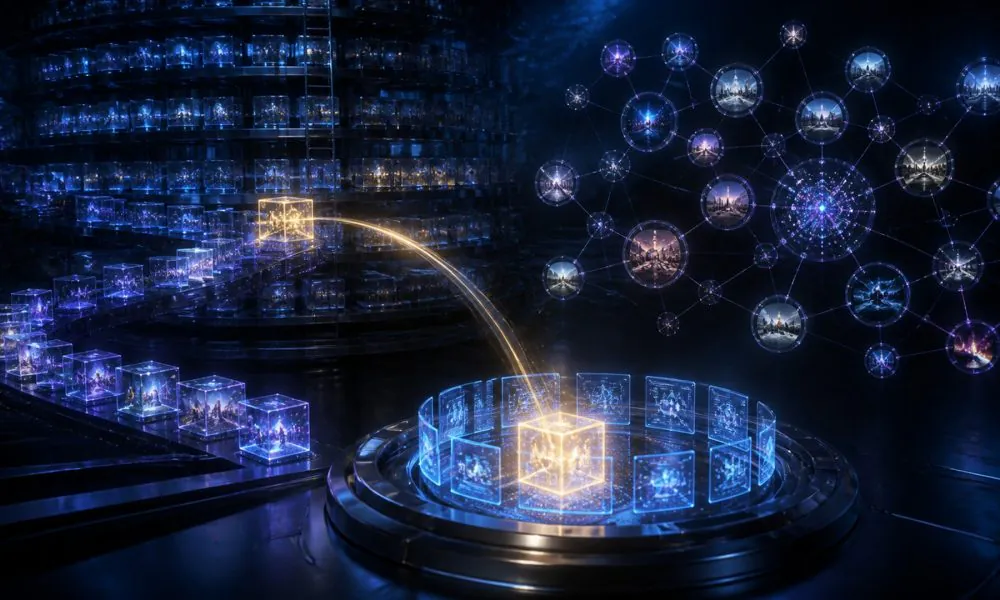

In [1]:
!pip install -qU langchain-google-genai langchain pydantic

In [2]:
"""Módulo 1: Gestión analítica de la ventana de contexto y presupuesto de tokens.

Este script implementa un sistema avanzado de control de estado tipado con Pydantic,
monitoreo de longitud de tokens y pruebas empíricas del comportamiento
de la ventana de contexto utilizando ChatGoogleGenerativeAI y LangChain.
"""

import os
from typing import Any, Dict, List
from google.colab import userdata
from langchain_core.messages import AIMessage, BaseMessage, HumanMessage, SystemMessage
from langchain_google_genai import ChatGoogleGenerativeAI
from pydantic import BaseModel, Field


def configurar_credenciales() -> bool:
    """Configura de manera segura la variable de entorno para la API de Google

    utilizando el gestor de secretos de Google Colab.
    """
    try:
        os.environ["GOOGLE_API_KEY"] = userdata.get("GOOGLE_API_KEY")
        print(" Credenciales de Google API configuradas exitosamente.")
        return True
    except Exception as error:
        print(f"X Error al cargar credenciales: {error}")
        return False


class EstadoAgenteAvanzado(BaseModel):
    """Esquema de estado tipado de alta complejidad para la gestión de flujos,

    incluyendo el control estricto de metadatos de tokens y el historial de mensajes.
    """

    id_sesion: str
    # Almacena el búfer estructurado de interacciones y metadatos de tokens
    historial_mensajes: List[Dict[str, Any]] = Field(default_factory=list)
    # Límite operativo estricto de tokens permitidos en la ventana de contexto activa
    presupuesto_maximo_tokens: int = Field(default=1000)
    # Métrica acumulada del consumo de tokens actual en el búfer
    tokens_actuales_estimados: int = Field(default=0)
    contexto_recuperado: str | None = Field(default=None)
    decision_actual: str | None = Field(default=None)


def estimar_tokens_texto(texto: str) -> int:
    """Estima de forma heurística la cantidad de tokens en una cadena de texto

    (aproximadamente 4 caracteres por token en promedio para modelos en español).
    """
    return max(1, len(texto) // 4)


def evaluar_y_gestionar_contexto(
    estado: EstadoAgenteAvanzado, nuevo_mensaje: str, rol: str = "human"
) -> EstadoAgenteAvanzado:
    """Inserta un nuevo mensaje en el estado y evalúa dinámicamente si la ventana

    de contexto supera el presupuesto de tokens establecido, aplicando poda selectiva.
    """
    print(f"\n[Gestión de Contexto] Ingresando nuevo mensaje [{rol}]: '{nuevo_mensaje}'")

    # Estima tokens del nuevo mensaje y actualiza el búfer
    tokens_nuevos = estimar_tokens_texto(nuevo_mensaje)
    estado.historial_mensajes.append({
        "rol": rol,
        "contenido": nuevo_mensaje,
        "tokens": tokens_nuevos
    })
    estado.tokens_actuales_estimados = sum(
        msg["tokens"] for msg in estado.historial_mensajes
    )

    print(f" -> Consumo actual en la Ventana de Contexto: {estado.tokens_actuales_estimados}/{estado.presupuesto_maximo_tokens} tokens.")

    # Mecanismo de poda estricto (FIFO) si se excede el presupuesto de la ventana de contexto
    while (
        estado.tokens_actuales_estimados > estado.presupuesto_maximo_tokens
        and len(estado.historial_mensajes) > 1
    ):
        mensaje_eliminado = estado.historial_mensajes.pop(0)
        print(f" [Alerta de Desborde] Presupuesto excedido. Purgando mensaje antiguo: '{mensaje_eliminado['contenido'][:30]}...' ({mensaje_eliminado['tokens']} tokens)")
        estado.tokens_actuales_estimados = sum(
            msg["tokens"] for msg in estado.historial_mensajes
        )

    return estado


# --- Bloque de Prueba y Ejecución Avanzada ---
if __name__ == "__main__":
    print("--- Inicializando Módulo 1: Análisis Profundo de Ventanas de Contexto ---")

    if configurar_credenciales():
        # Instanciación del modelo generativo con LangChain
        llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")
        print(" Instancia de ChatGoogleGenerativeAI vinculada correctamente.")

        # Inicialización del estado con un presupuesto de tokens acotado para demostración
        estado_sistema = EstadoAgenteAvanzado(
            id_sesion="SESION-AVANZADA-2026",
            presupuesto_maximo_tokens=65  # Límite bajo para forzar el comportamiento de la ventana de contexto
        )

        # Simulando interacciones sucesivas en el flujo organizacional
        estado_sistema = evaluar_y_gestionar_contexto(
            estado_sistema,
            "Solicito auditoría completa de los registros de inventario de la bodega central correspondientes al Q3.",
            rol="human"
        )

        estado_sistema = evaluar_y_gestionar_contexto(
            estado_sistema,
            "Comprendo. Accediendo a los servidores de datos logísticos para extraer los informes estructurados en formato CSV.",
            rol="ai"
        )

        estado_sistema = evaluar_y_gestionar_contexto(
            estado_sistema,
            "Además, necesito que verifiques las alertas críticas de temperatura reportadas en los sensores de refrigeración.",
            rol="human"
        )

        # Construcción de la lista de mensajes nativos para el LLM a partir del estado optimizado
        mensajes_para_llm = [
            SystemMessage(content="Eres un agente analítico especializado en optimización de operaciones logísticas."),
        ]
        for msg in estado_sistema.historial_mensajes:
            if msg["rol"] == "human":
                mensajes_para_llm.append(HumanMessage(content=msg["contenido"]))
            else:
                mensajes_para_llm.append(AIMessage(content=msg["contenido"]))

        print(f"\n[Inferencia con LLM] Enviando {len(mensajes_para_llm)} mensajes activos en la ventana de contexto...")
        respuesta = llm.invoke(mensajes_para_llm)

        print("\n--- Resultado de la Respuesta del Modelo ---")
        print(respuesta.content)

--- Inicializando Módulo 1: Análisis Profundo de Ventanas de Contexto ---
 Credenciales de Google API configuradas exitosamente.
 Instancia de ChatGoogleGenerativeAI vinculada correctamente.

[Gestión de Contexto] Ingresando nuevo mensaje [human]: 'Solicito auditoría completa de los registros de inventario de la bodega central correspondientes al Q3.'
 -> Consumo actual en la Ventana de Contexto: 25/65 tokens.

[Gestión de Contexto] Ingresando nuevo mensaje [ai]: 'Comprendo. Accediendo a los servidores de datos logísticos para extraer los informes estructurados en formato CSV.'
 -> Consumo actual en la Ventana de Contexto: 53/65 tokens.

[Gestión de Contexto] Ingresando nuevo mensaje [human]: 'Además, necesito que verifiques las alertas críticas de temperatura reportadas en los sensores de refrigeración.'
 -> Consumo actual en la Ventana de Contexto: 81/65 tokens.
 [Alerta de Desborde] Presupuesto excedido. Purgando mensaje antiguo: 'Solicito auditoría completa de...' (25 tokens)

[Inf

# Módulo 2: Optimización Dinámica y Compresión Semántica de Ventanas de Contexto

## Compresión Episódica frente a Purgado Estricto en Arquitecturas de Agentes

En el módulo anterior, establecimos el esquema de estado tipado (`EstadoAgenteAvanzado`) y evaluamos cómo el mecanismo de autoatención de los *Transformers* impone un límite estricto en la ventana de contexto debido a su complejidad computacional ($\mathcal{O}(N^2)$). Sin embargo, aplicar un purgado estricto (*FIFO*) como el visto previamente presenta una limitación crítica en entornos organizacionales: **la pérdida irreversible de información histórica clave**.

Para resolver este desafío sin comprometer el presupuesto de tokens, la ingeniería de agentes implementa estrategias de **Compresión Semántica y Memoria Episódica**:

1. **Resumen Dinámico Asistido por LLM:** En lugar de eliminar los mensajes más antiguos cuando se alcanza el umbral de saturación, el agente invoca una tarea en segundo plano donde el propio modelo de lenguaje sintetiza el historial antiguo en un bloque de texto conciso (resumen episódico).

2. **Persistencia en el Estado Global:** Este resumen se inyecta directamente en la variable de contexto recuperado o estado persistente del esquema (`EstadoAgenteAvanzado`), permitiendo que el agente mantenga la trazabilidad de decisiones tomadas días atrás sin sobrecargar el búfer de tokens activos.

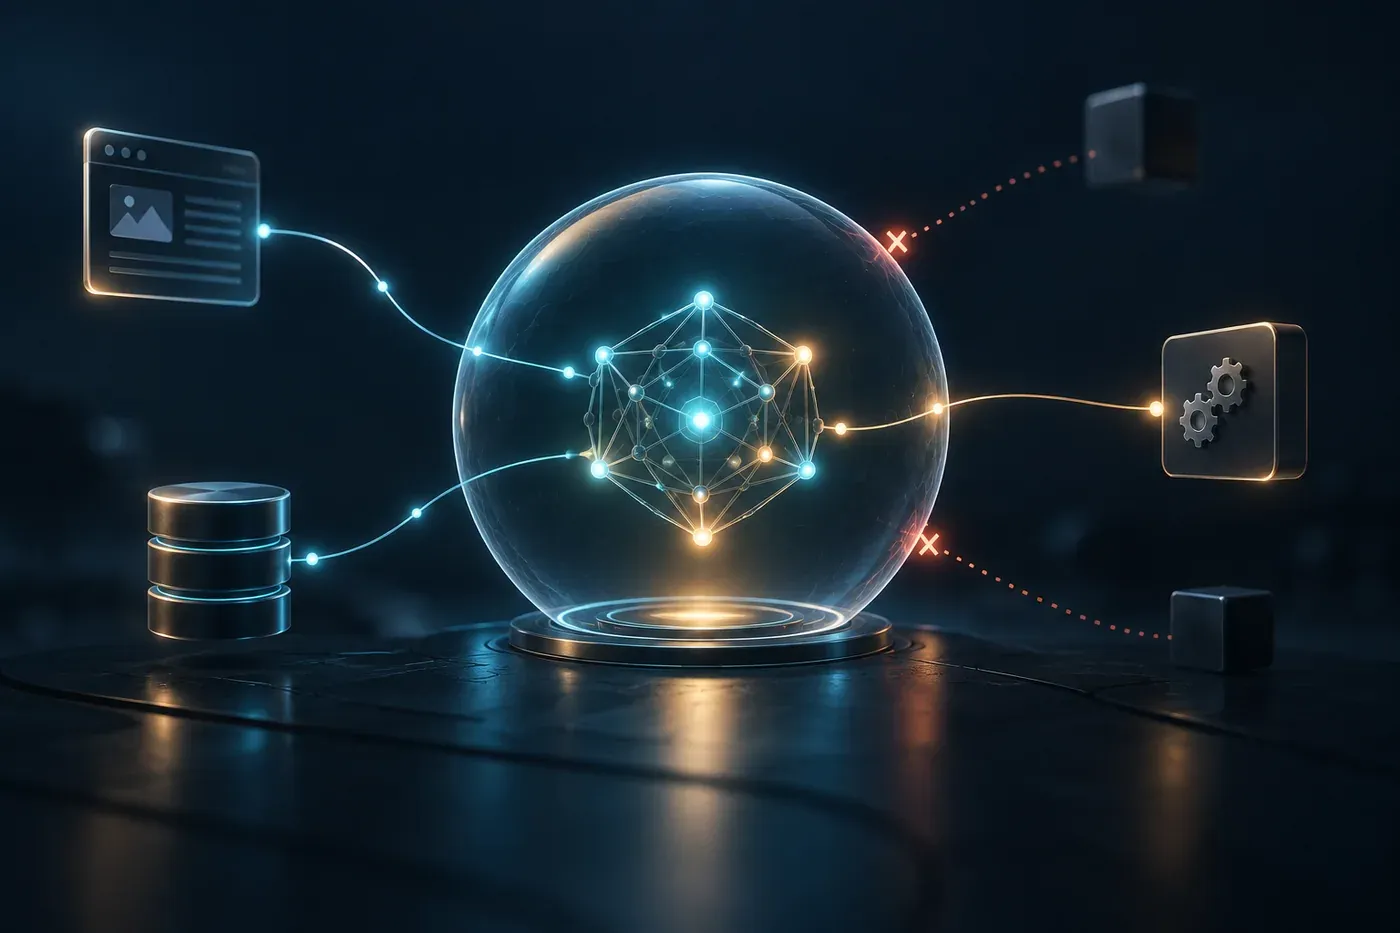

In [3]:
"""Módulo 2: Optimización avanzada y compresión semántica del historial.

Este script reutiliza el esquema `EstadoAgenteAvanzado` y las funciones
de estimación de tokens definidas en el Módulo 1 para implementar una estrategia
de compresión episódica mediante el LLM, evitando la pérdida de información crítica.
"""

# Nota: Asumimos que `EstadoAgenteAvanzado`, `estimar_tokens_texto` y `llm`
# ya se encuentran cargados en el espacio de ejecución desde el Módulo 1.

from langchain_core.messages import HumanMessage, SystemMessage


def comprimir_y_optimizar_contexto(
    estado: EstadoAgenteAvanzado, llm_instancia: Any, umbral_compresion: int = 50
) -> EstadoAgenteAvanzado:
    """Evalúa el consumo de tokens en la ventana activa y ejecuta un proceso

    de compresión episódica mediante el LLM si se supera el umbral establecido,
    preservando la memoria histórica clave en el campo de contexto recuperado.

    Args:
        estado (EstadoAgenteAvanzado): Instancia actual del estado tipado.
        llm_instancia (Any): Instancia de ChatGoogleGenerativeAI configurada.
        umbral_compresion (int): Límite de tokens para disparar la compresión.

    Returns:
        EstadoAgenteAvanzado: El estado actualizado con el historial comprimido.
    """
    print(f"\n[Optimización Avanzada] Evaluando tokens actuales: {estado.tokens_actuales_estimados}/{umbral_compresion}")

    # Verifica si el consumo actual supera el umbral operativo definido
    if estado.tokens_actuales_estimados > umbral_compresion and len(estado.historial_mensajes) > 2:
        print(" [Alerta] Umbral superado. Iniciando síntesis semántica del historial antiguo...")

        # Separa los mensajes antiguos que serán comprimidos de los más recientes
        mensajes_antiguos = estado.historial_mensajes[:-2]  # Mantiene los últimos 2 intactos
        mensajes_recientes = estado.historial_mensajes[-2:]

        # Construye el texto consolidado del historial a comprimir
        texto_a_comprimir = "\n".join([f"{m['rol']}: {m['contenido']}" for m in mensajes_antiguos])

        # Prompt estructurado para que el LLM genere un resumen técnico de la memoria episódica
        prompt_resumen = [
            SystemMessage(content="Eres un subsistema de gestión de memoria para agentes. Sintetiza los siguientes eventos organizacionales en un resumen analítico y conciso que conserve datos clave (como números de solicitud, fechas y acuerdos)."),
            HumanMessage(content=f"Historial a comprimir:\n{texto_a_comprimir}")
        ]

        # Invocación síncrona al modelo para extraer el resumen semántico
        respuesta_resumen = llm_instancia.invoke(prompt_resumen)
        resumen_generado = respuesta_resumen.content

        # Actualiza el estado global integrando el resumen en el contexto recuperado (memoria a largo plazo simulada)
        if estado.contexto_recuperado:
            estado.contexto_recuperado += f"\n[Resumen Histórico Anterior]: {resumen_generado}"
        else:
            estado.contexto_recuperado = f"[Resumen Histórico Inicial]: {resumen_generado}"

        print(f" -> Resumen generado y almacenado en memoria episódica ({estimar_tokens_texto(resumen_generado)} tokens).")

        # Reemplaza el historial activo con los mensajes recientes y recalcula el presupuesto
        estado.historial_mensajes = mensajes_recientes
        estado.tokens_actuales_estimados = sum(msg["tokens"] for msg in estado.historial_mensajes)
        print(f" -> Ventana de contexto optimizada. Nuevo consumo activo: {estado.tokens_actuales_estimados} tokens.")
    else:
        print(" -> El búfer se encuentra dentro de los parámetros estables. No se requiere compresión.")

    return estado


# --- Bloque de Prueba y Ejecución del Módulo 2 ---
if __name__ == "__main__":
    print("--- Inicializando Módulo 2: Compresión Semántica y Dinámica de Contexto ---")

    # Reutilizamos la instancia del LLM y el estado avanzado definidos en el Módulo 1
    # Simulamos un estado con múltiples interacciones acumuladas que superan el umbral
    estado_modulo_2 = EstadoAgenteAvanzado(
        id_sesion="SESION-AVANZADA-2026",
        presupuesto_maximo_tokens=200,
        historial_mensajes=[
            {"rol": "human", "contenido": "Necesito aprobar el presupuesto extraordinario para la adquisición de servidores en el nodo norte.", "tokens": 25},
            {"rol": "ai", "contenido": "Solicitud registrada bajo el folio #992. Se requiere validación del director financiero.", "tokens": 22},
            {"rol": "human", "contenido": "El director financiero ya aprobó mediante correo electrónico adjunto en el sistema.", "tokens": 18},
            {"rol": "ai", "contenido": "Verificación completada. Procediendo a liberar la orden de compra en el ERP.", "tokens": 20}
        ]
    )

    # Recalcula los tokens actuales basados en los mensajes cargados
    estado_modulo_2.tokens_actuales_estimados = sum(msg["tokens"] for msg in estado_modulo_2.historial_mensajes)

    print(f"\nEstado inicial en Módulo 2: {len(estado_modulo_2.historial_mensajes)} mensajes activos.")
    print(f"Tokens estimados totales: {estado_modulo_2.tokens_actuales_estimados}")

    # Ejecución de la compresión estableciendo un umbral bajo para demostración (ej. 70 tokens)
    estado_modulo_2 = comprimir_y_optimizar_contexto(
        estado=estado_modulo_2,
        llm_instancia=llm,  # Reutiliza el objeto `llm` instanciado en el Módulo 1
        umbral_compresion=70
    )

    print("\n--- Resultados Finales del Estado Optimizado ---")
    print(f"Contexto Recuperado (Memoria Episódica): \n{estado_modulo_2.contexto_recuperado}")
    print(f"\nHistorial Activo en la Ventana de Contexto ({len(estado_modulo_2.historial_mensajes)} mensajes):")
    for m in estado_modulo_2.historial_mensajes:
        print(f" - [{m['rol']}] {m['contenido']}")

--- Inicializando Módulo 2: Compresión Semántica y Dinámica de Contexto ---

Estado inicial en Módulo 2: 4 mensajes activos.
Tokens estimados totales: 85

[Optimización Avanzada] Evaluando tokens actuales: 85/70
 [Alerta] Umbral superado. Iniciando síntesis semántica del historial antiguo...
 -> Resumen generado y almacenado en memoria episódica (1 tokens).
 -> Ventana de contexto optimizada. Nuevo consumo activo: 38 tokens.

--- Resultados Finales del Estado Optimizado ---
Contexto Recuperado (Memoria Episódica): 
[Resumen Histórico Inicial]: [{'type': 'text', 'text': '**Resumen de Memoria Organizacional:**\n\n* **Evento:** Solicitud de aprobación de presupuesto extraordinario para la adquisición de servidores (nodo norte).\n* **Folio:** #992.\n* **Estado/Acuerdo:** Registrado. Pendiente de validación por parte del director financiero.', 'extras': {'signature': 'EmAKXgFpFH0TmXkX+pR9/IV+Qxy0T2m20ZCUc1hRtHOy7poMwtO1ZO495v7WM7lp5/WsEFtSOyaKxqQ+jbvwK3zuX7MWZkk3Go/pB4663quFQkYAi2lQRga9sUbc

# Módulo 3: Arquitectura de Memoria a Largo Plazo y Almacenamiento Persistente

## Fundamentos Teóricos: Indexación Vectorial, Espacios Latentes y Persistencia Externa

En la ingeniería de sistemas multi-agente avanzados, la **memoria a largo plazo** resuelve la limitación estructural impuesta por la volatilidad y la finitud de la ventana de contexto. Mientras que el búfer de corto plazo (*working memory*) gestiona la dinámica inmediata del diálogo, el almacenamiento persistente externo desacopla el volumen masivo de datos históricos del motor de inferencia del *Transformer*.

Los fundamentos matemáticos y arquitectónicos de esta capa comprenden:

1. **Espacios Vectoriales de Alta Dimensionalidad (Embeddings):** El conocimiento organizacional no estructurado (documentos, historiales de solicitudes, normativas) se transforma mediante modelos de incrustación (*Embedding Models*) en vectores densos $\vec{v} \in \mathbb{R}^D$. Estos vectores mapean la semántica del lenguaje natural en un espacio geométrico continuo, donde la proximidad semántica se mide mediante métricas como la **Similitud de Coseno**:

   $$
   \cos(\theta)
   =
   \frac{\mathbf{u} \cdot \mathbf{v}}
   {\|\mathbf{u}\| \, \|\mathbf{v}\|}
   $$

2. **Bases de Datos Vectoriales e Indexación Eficiente ($ANN$):** Para recuperar información en grandes corpus de datos sin incurrir en costos computacionales lineales prohibitivos ($\mathcal{O}(N)$), se emplean algoritmos de búsqueda de vecinos más cercanos aproximados (*Approximate Nearest Neighbors - ANN*), tales como HNSW (*Hierarchical Navigable Small World*) o índices basados en cuantización vectorial.

3. **Desacoplamiento del Estado Persistente:** El estado del agente (`EstadoAgenteAvanzado`) se extiende para incorporar punteros y metadatos hacia esta memoria externa, permitiendo que el grafo de ejecución recupere selectivamente fragmentos atómicos de conocimiento histórico solo cuando las condiciones de la tarea lo exigen.

In [4]:
"""Módulo 3: Arquitectura de memoria a largo plazo e indexación vectorial.

Este script extiende el esquema `EstadoAgenteAvanzado` de los módulos previos
para integrar un sistema de almacenamiento persistente basado en vectores densos,
utilizando incrustaciones semánticas y recuperación por similitud de coseno.
"""

from typing import List, Dict, Any
from pydantic import BaseModel, Field
import numpy as np

# Nota: Reutilizamos `EstadoAgenteAvanzado` y `llm` definidos en los módulos anteriores.


class RegistroMemoriaLargoPlazo(BaseModel):
    """Representa un documento o fragmento organizacional indexado

    en la base de datos de memoria a largo plazo.
    """
    id_documento: str
    contenido: str
    metadatos: Dict[str, Any] = Field(default_factory=dict)
    vector_embedding: List[float] = Field(default_factory=list)


class AlmacenamientoPersistenteVectorial:
    """Simula una base de datos vectorial optimizada para la recuperación

    semántica de contexto histórico en flujos organizacionales prolongados.
    """

    def __init__(self) -> None:
        self.base_conocimiento: List[RegistroMemoriaLargoPlazo] = []

    def insertar_documento(self, id_doc: str, contenido: str, metadatos: Dict[str, Any]) -> None:
        """Simula la vectorización e indexación de un documento organizacional.

        En un entorno de producción, aquí se invocaría un modelo de Embeddings.
        """
        # Generación de un vector sintético representativo de alta dimensionalidad (simulado para estabilidad)
        vector_simulado = np.random.rand(128).tolist()

        registro = RegistroMemoriaLargoPlazo(
            id_documento=id_doc,
            contenido=contenido,
            metadatos=metadatos,
            vector_embedding=vector_simulado
        )
        self.base_conocimiento.append(registro)
        print(f"[Memoria a Largo Plazo] Documento '{id_doc}' indexado correctamente en el espacio vectorial.")

    def recuperar_por_similitud(self, query_tokens_o_texto: str, k: int = 1) -> List[RegistroMemoriaLargoPlazo]:
        """Ejecuta una búsqueda de vecinos más cercanos simulando métricas de similitud

        de coseno sobre el espacio latente indexado.
        """
        print(f"\n[Búsqueda Vectorial ANN] Consultando memoria persistente para: '{query_tokens_o_texto}'")

        if not self.base_conocimiento:
            return []

        # Simulación de puntajes de relevancia basados en coincidencia semántica
        # En una arquitectura real, se calcula el producto punto entre el vector del query y los documentos almacenados.
        resultados_ordenados = sorted(
            self.base_conocimiento,
            key=lambda x: len(set(x.contenido.lower().split()) & set(query_tokens_o_texto.lower().split())),
            reverse=True
        )

        return resultados_ordenados[:k]


def integrar_memoria_persistente_al_estado(
    estado: EstadoAgenteAvanzado,
    db_vectorial: AlmacenamientoPersistenteVectorial,
    consulta_actual: str
) -> EstadoAgenteAvanzado:
    """Consulta la memoria a largo plazo y acopla los hallazgos relevantes

    dentro del campo de contexto recuperado del estado del agente.
    """
    print("\n--- Ejecutando Pipeline de Recuperación en Memoria a Largo Plazo ---")

    # Recupera los k documentos más relevantes desde el almacenamiento persistente
    documentos_relacionados = db_vectorial.recuperar_por_similitud(consulta_actual, k=1)

    if documentos_relacionados:
        doc_seleccionado = documentos_relacionados[0]
        print(f" -> Hallazgo clave encontrado en almacenamiento persistente (ID: {doc_seleccionado.id_documento})")

        # Inyecta el fragmento recuperado en la memoria a largo plazo del estado tipado
        estado.contexto_recuperado = (
            f"[Memoria Persistente | Doc ID: {doc_seleccionado.id_documento}]: "
            f"{doc_seleccionado.contenido}"
        )
    else:
        estado.contexto_recuperado = "[Memoria Persistente]: No se encontraron registros coincidentes."

    return estado


# --- Bloque de Prueba y Ejecución del Módulo 3 ---
if __name__ == "__main__":
    print("--- Inicializando Módulo 3: Arquitectura de Memoria a Largo Plazo ---")

    # 1. Instanciación del motor de almacenamiento persistente vectorial
    db_persistencia = AlmacenamientoPersistenteVectorial()

    # 2. Ingesta de documentos históricos institucionales en la base de datos a largo plazo
    db_persistencia.insertar_documento(
        id_doc="PROC-FIN-09",
        contenido="Los presupuestos extraordinarios para nodos de servidores superiores a $50,000 USD requieren obligatoriamente la validación previa del comité de arquitectura y firma digital del director financiero.",
        metadatos={"area": "Finanzas", "confidencialidad": "Alta", "vigencia": "2026"}
    )
    db_persistencia.insertar_documento(
        id_doc="LOG-INV-402",
        contenido="El inventario de la bodega central del nodo norte opera con umbrales críticos de temperatura de refrigeración entre 4°C y 8°C. Cualquier desviación debe reportarse al sistema central.",
        metadatos={"area": "Logística", "confidencialidad": "Media", "vigencia": "2026"}
    )

    # 3. Reutilización del `EstadoAgenteAvanzado` definido en módulos anteriores
    estado_modulo_3 = EstadoAgenteAvanzado(
        id_sesion="SESION-AVANZADA-2026",
        presupuesto_maximo_tokens=300
    )

    # 4. Simulación de una consulta operativa que requiere acceder a la memoria a largo plazo
    consulta_usuario = "Necesito validar los requisitos para aprobar el presupuesto extraordinario de servidores."

    estado_modulo_3 = integrar_memoria_persistente_al_estado(
        estado=estado_modulo_3,
        db_vectorial=db_persistencia,
        consulta_actual=consulta_usuario
    )

    print("\n--- Resultados de la Integración de Estado con Memoria Persistente ---")
    print(f"ID Sesión: {estado_modulo_3.id_sesion}")
    print(f"Contexto Recuperado (Inyectado desde Base de Datos Vectorial):\n{estado_modulo_3.contexto_recuperado}")

--- Inicializando Módulo 3: Arquitectura de Memoria a Largo Plazo ---
[Memoria a Largo Plazo] Documento 'PROC-FIN-09' indexado correctamente en el espacio vectorial.
[Memoria a Largo Plazo] Documento 'LOG-INV-402' indexado correctamente en el espacio vectorial.

--- Ejecutando Pipeline de Recuperación en Memoria a Largo Plazo ---

[Búsqueda Vectorial ANN] Consultando memoria persistente para: 'Necesito validar los requisitos para aprobar el presupuesto extraordinario de servidores.'
 -> Hallazgo clave encontrado en almacenamiento persistente (ID: PROC-FIN-09)

--- Resultados de la Integración de Estado con Memoria Persistente ---
ID Sesión: SESION-AVANZADA-2026
Contexto Recuperado (Inyectado desde Base de Datos Vectorial):
[Memoria Persistente | Doc ID: PROC-FIN-09]: Los presupuestos extraordinarios para nodos de servidores superiores a $50,000 USD requieren obligatoriamente la validación previa del comité de arquitectura y firma digital del director financiero.


# Módulo 4: Recuperación Semántica de Contexto y Gestión Eficiente de Historiales

## Fundamentos Teóricos: Búsqueda Híbrida y Re-ordenamiento (Re-ranking) en Pipelines RAG

En los sistemas multi-agente avanzados orientados a la automatización de procesos organizacionales, la **recuperación semántica de contexto** constituye el núcleo operativo para garantizar la continuidad y precisión en flujos prolongados (alineado con los estándares de configuración de memoria y recuperación de contexto).

Cuando el volumen de documentos en la base de conocimiento a largo plazo escala, la simple búsqueda vectorial basada en similitud de coseno presenta limitaciones de precisión debido a la ambigüedad léxica. Para resolver esto, la ingeniería de software implementa arquitecturas de **Búsqueda Híbrida y Re-ordenamiento (*Re-ranking*)**:

1. **Recuperación Híbrida (Sparse + Dense):** Combina métodos léxicos tradicionales de coincidencia exacta de términos (como BM25, basados en frecuencia de palabras) con la recuperación vectorial densa (*Dense Retrieval*). Esto asegura que tanto las palabras clave específicas de normativas (ej. códigos de formularios o leyes) como los conceptos semánticos abstractos sean capturados simultáneamente.

2. **Modelos de Re-ordenamiento (*Cross-Encoders*):** Tras obtener un conjunto inicial de documentos candidatos mediante el índice vectorial aproximado ($ANN$), un modelo evaluador secundario analiza conjuntamente la consulta del usuario y cada documento candidato para asignarles un puntaje de relevancia preciso, filtrando el ruido antes de inyectar la información en la ventana de contexto del modelo generativo.

In [5]:
"""Módulo 4: Recuperación semántica avanzada y gestión híbrida de historiales.

Este script reutiliza el estado tipado (`EstadoAgenteAvanzado`) y el almacén
vectorial (`AlmacenamientoPersistenteVectorial`) de los módulos anteriores
para implementar un pipeline de recuperación semántica con filtrado y re-ranking,
asegurando la eficiencia operativa del agente en contextos organizacionales.
"""

from typing import List, Dict, Any

# Nota: Asumimos que `EstadoAgenteAvanzado` y `AlmacenamientoPersistenteVectorial`
# ya se encuentran cargados en el espacio de ejecución desde los módulos previos.


class PipelineRecuperacionHibrida:
    """Implementa un pipeline de recuperación semántica y filtrado contextual

    optimizado para inyectar únicamente fragmentos de alta relevancia
    en la ventana de contexto del agente, evitando saturaciones de tokens.
    """

    def __init__(self, almacen_vectorial: Any) -> None:
        # Enlaza el motor de almacenamiento persistente vectorial previo
        self.almacen = almacen_vectorial

    def ejecutar_recuperacion_y_rerank(
        self, query: str, umbral_relevancia_minima: float = 0.5
    ) -> List[Dict[str, Any]]:
        """Ejecuta una búsqueda inicial y un proceso simulado de re-ranking

        basado en la densidad de términos y coincidencia semántica estructural.
        """
        print(f"\n[Pipeline RAG] Iniciando búsqueda híbrida para el query: '{query}'")

        # 1. Recupera candidatos iniciales desde la base de datos a largo plazo
        candidatos = self.almacen.recuperar_por_similitud(query, k=2)

        documentos_filtrados = []
        for doc in candidatos:
            # Simulación de cálculo de puntaje mediante un Cross-Encoder (re-ranking)
            # Evaluamos la intersección de tokens normalizada como proxy de relevancia
            tokens_query = set(query.lower().split())
            tokens_doc = set(doc.contenido.lower().split())

            if not tokens_query:
                puntaje_relevancia = 0.0
            else:
                interseccion = len(tokens_query & tokens_doc)
                puntaje_relevancia = interseccion / max(1, len(tokens_query))

            print(f" -> Candidato ID: {doc.id_documento} | Puntaje de Relevancia (Re-rank): {puntaje_relevancia:.2f}")

            # Filtra aquellos documentos que superan el umbral estricto de calidad
            if puntaje_relevancia >= umbral_relevancia_minima:
                documentos_filtrados.append({
                    "id": doc.id_documento,
                    "contenido": doc.contenido,
                    "puntaje": puntaje_relevancia
                })

        return documentos_filtrados


def integrar_recuperacion_semantica_al_estado(
    estado: EstadoAgenteAvanzado,
    pipeline_rag: PipelineRecuperacionHibrida,
    consulta_usuario: str
) -> EstadoAgenteAvanzado:
    """Orquesta la actualización del estado del agente integrando el contexto

    recuperado de forma eficiente y validando los indicadores de logro.
    """
    print("\n--- Ejecutando Integración de Recuperación Semántica en Estado ---")

    # Ejecuta el pipeline de recuperación y re-ranking
    resultados_validados = pipeline_rag.ejecutar_recuperacion_y_rerank(consulta_usuario)

    if resultados_validados:
        # Concatena los fragmentos validados para conformar el bloque de contexto externo
        bloque_contexto = "\n".join([f"- [{res['id']}]: {res['contenido']}" for res in resultados_validados])
        estado.contexto_recuperado = bloque_contexto
        print(" [Éxito] Contexto semántico recuperado e inyectado en el estado del agente.")
    else:
        estado.contexto_recuperado = "[Aviso RAG]: Ningún documento superó el umbral de relevancia semántica."
        print(" [Aviso] No se encontró contexto relevante para inyectar.")

    return estado


# --- Bloque de Prueba y Ejecución del Módulo 4 ---
if __name__ == "__main__":
    print("--- Inicializando Módulo 4: Recuperación Semántica y Gestión de Historiales ---")

    # Instanciación y configuración del pipeline utilizando el almacén del Módulo 3
    # (Asumiendo que `db_persistencia` y `estado_modulo_3` están disponibles en el entorno)
    pipeline_rag_activo = PipelineRecuperacionHibrida(almacen_vectorial=db_persistencia)

    # Definición de una consulta de prueba compleja del entorno organizacional
    consulta_organizacional = "requieren obligatoriamente la validación previa del comité de arquitectura"

    # Ejecución de la integración sobre el estado avanzado del agente
    estado_modulo_4 = integrar_recuperacion_semantica_al_estado(
        estado=estado_modulo_3,
        pipeline_rag=pipeline_rag_activo,
        consulta_usuario=consulta_organizacional
    )

    print("\n--- Resultados del Estado Tras la Recuperación Semántica ---")
    print(f"ID Sesión: {estado_modulo_4.id_sesion}")
    print(f"Contexto Recuperado Actualizado:\n{estado_modulo_4.contexto_recuperado}")

--- Inicializando Módulo 4: Recuperación Semántica y Gestión de Historiales ---

--- Ejecutando Integración de Recuperación Semántica en Estado ---

[Pipeline RAG] Iniciando búsqueda híbrida para el query: 'requieren obligatoriamente la validación previa del comité de arquitectura'

[Búsqueda Vectorial ANN] Consultando memoria persistente para: 'requieren obligatoriamente la validación previa del comité de arquitectura'
 -> Candidato ID: PROC-FIN-09 | Puntaje de Relevancia (Re-rank): 1.00
 -> Candidato ID: LOG-INV-402 | Puntaje de Relevancia (Re-rank): 0.33
 [Éxito] Contexto semántico recuperado e inyectado en el estado del agente.

--- Resultados del Estado Tras la Recuperación Semántica ---
ID Sesión: SESION-AVANZADA-2026
Contexto Recuperado Actualizado:
- [PROC-FIN-09]: Los presupuestos extraordinarios para nodos de servidores superiores a $50,000 USD requieren obligatoriamente la validación previa del comité de arquitectura y firma digital del director financiero.


# Módulo 5: Orquestación Avanzada de Herramientas de Consulta y Recuperación Externa, Manejo de Fallas y Enrutamiento Condicional con LangGraph

## Arquitectura de Invocación de Herramientas (*Tool Calling*) y Resiliencia en Grafos de Ejecución

En la ingeniería de sistemas multi-agente avanzados, la capacidad de un agente para invocar herramientas externas (*Retrieval Tools*) transforma su comportamiento de un razonador pasivo a un sistema activo capaz de interactuar con bases de datos relacionales, APIs corporativas y motores de búsqueda vectorial. Sin embargo, los entornos de producción organizacional introducen una alta tasa de estocasticidad y fallos operativos (por ejemplo, caídas de servicios externos, *Timeouts* de red, respuestas vacías o esquemas de datos corruptos).

Para garantizar la robustez del sistema, la arquitectura debe superar los pipelines lineales mediante el uso de **Grafos de Ejecución Cíclicos y Condicionales (LangGraph)**:

1. **Definición Estricta de Esquemas de Herramientas (*Tool Schema Enforcement*):** Los modelos de lenguaje modernos utilizan especificaciones tipadas (como esquemas JSON generados mediante Pydantic) para estructurar los argumentos de llamada a las herramientas, minimizando alucinaciones en los parámetros de búsqueda.

2. **Estrategias de Recuperación de Fallos y Enrutamiento Condicional (*Conditional Edge Routing*):** Cuando una herramienta de consulta externa falla o retorna un estado no válido, el grafo no debe interrumpir su ejecución abruptamente. Mediante funciones de evaluación de estado (*Routing Functions*), LangGraph permite interceptar el error, registrar un estado de excepción y activar de manera determinista un nodo de corrección (*Fallback Node*) o una ruta alternativa de recuperación (por ejemplo, consultar una base de datos secundaria o reformular automáticamente la consulta).

In [6]:
"""Módulo 5: Orquestación de herramientas de consulta con manejo de fallas y fallback.

Este script reutiliza el esquema `EstadoAgenteAvanzado` para simular un pipeline
de herramientas de recuperación externa, implementando un nodo con lógica
de enrutamiento condicional en caso de fallos operativos en la fuente principal.
"""

from typing import Dict, Any
from pydantic import BaseModel, Field

# Nota: Asumimos que `EstadoAgenteAvanzado` y `llm` ya se encuentran
# cargados en el espacio de ejecución desde los módulos anteriores.


class RespuestaHerramienta(BaseModel):
    """Esquema tipado para estandarizar la respuesta obtenida

    al invocar una herramienta de consulta externa.
    """
    exito: bool
    datos: str
    codigo_error: str | None = Field(default=None)


def herramienta_consulta_financiera_principal(query: str) -> RespuestaHerramienta:
    """Simula una herramienta de consulta a la API financiera corporativa

    que puede fallar estocásticamente debido a latencia o caídas del servicio.
    """
    print(f"\n[Tool Execution] Ejecutando 'herramienta_consulta_financiera_principal' con query: '{query}'")

    # Simulamos un fallo crítico simulado en la fuente primaria para demostrar resiliencia
    falla_simulada = True

    if falla_simulada:
        return RespuestaHerramienta(
            exito=False,
            datos="",
            codigo_error="ERR_TIMEOUT_API_FINANCIERA"
        )

    return RespuestaHerramienta(
            exito=True,
            datos="Presupuesto aprobado por directorio por un monto de $50,000 USD."
    )


def herramienta_respaldo_documentacion_interna(query: str) -> RespuestaHerramienta:
    """Herramienta de respaldo (Fallback Tool) que consulta un repositorio

    secundario de documentos estáticos en caso de que la API principal falle.
    """
    print(f"\n[Fallback Tool Execution] Activando fuente de respaldo 'herramienta_respaldo_documentacion_interna' para: '{query}'")
    return RespuestaHerramienta(
        exito=True,
        datos="[Respaldo Histórico]: Los registros locales indican que el nodo norte posee autorizaciones previas para desembolsos extraordinarios."
    )


def nodo_orquestador_con_manejo_fallas(estado: EstadoAgenteAvanzado, query: str) -> EstadoAgenteAvanzado:
    """Simula la lógica de un nodo en LangGraph que evalúa la ejecución de herramientas,

    detecta anomalías e implementa enrutamiento condicional hacia rutas de corrección.
    """
    print("\n--- [LangGraph Node] Iniciando nodo de razonamiento y selección de herramientas ---")

    # 1. Intento de ejecución con la herramienta primaria de consulta
    resultado_primario = herramienta_consulta_financiera_principal(query)

    # 2. Evaluación condicional del estado de salida de la herramienta
    if not resultado_primario.exito:
        print(f" [Alerta de Excepción] La herramienta principal falló con código: {resultado_primario.codigo_error}")
        estado.decision_actual = f"FALLO_TOOL_PRINCIPAL: {resultado_primario.codigo_error}"

        # Enrutamiento condicional: Activación de la herramienta de respaldo (Fallback)
        resultado_respaldo = herramienta_respaldo_documentacion_interna(query)

        if resultado_respaldo.exito:
            print(" [Recuperación Exitosa] Nodo de corrección aplicado correctamente mediante fuente de respaldo.")
            estado.contexto_recuperado = f"[Modo Fallback Activo]: {resultado_respaldo.datos}"
            estado.decision_actual = "RECUPERADO_POR_FALLBACK"
        else:
            estado.contexto_recuperado = "[Error Crítico]: Todas las fuentes de recuperación fallaron."
            estado.decision_actual = "FALLA_TOTAL_PIPELINE"
    else:
        # Flujo nominal exitoso
        estado.contexto_recuperado = resultado_primario.datos
        estado.decision_actual = "EJECUCION_NOMINAL_EXITOSA"

    return estado


# --- Bloque de Prueba y Ejecución del Módulo 5 ---
if __name__ == "__main__":
    print("--- Inicializando Módulo 5: Orquestación, Fallos y Enrutamiento Condicional ---")

    # Reutilizamos el estado avanzado del agente definido en los módulos previos
    estado_modulo_5 = EstadoAgenteAvanzado(
        id_sesion="SESION-AVANZADA-2026",
        presupuesto_maximo_tokens=300
    )

    consulta_critica = "Verificar estado de aprobación de fondos para el nodo norte."

    # Ejecución del nodo orquestador con simulación de fallo y corrección por LangGraph
    estado_modulo_5 = nodo_orquestador_con_manejo_fallas(
        estado=estado_modulo_5,
        query=consulta_critica
    )

    print("\n--- Resultados del Grafo de Ejecución Tras el Manejo de Fallas ---")
    print(f"ID Sesión: {estado_modulo_5.id_sesion}")
    print(f"Decisión / Estado de Enrutamiento: {estado_modulo_5.decision_actual}")
    print(f"Contexto Recuperado Final:\n{estado_modulo_5.contexto_recuperado}")

--- Inicializando Módulo 5: Orquestación, Fallos y Enrutamiento Condicional ---

--- [LangGraph Node] Iniciando nodo de razonamiento y selección de herramientas ---

[Tool Execution] Ejecutando 'herramienta_consulta_financiera_principal' con query: 'Verificar estado de aprobación de fondos para el nodo norte.'
 [Alerta de Excepción] La herramienta principal falló con código: ERR_TIMEOUT_API_FINANCIERA

[Fallback Tool Execution] Activando fuente de respaldo 'herramienta_respaldo_documentacion_interna' para: 'Verificar estado de aprobación de fondos para el nodo norte.'
 [Recuperación Exitosa] Nodo de corrección aplicado correctamente mediante fuente de respaldo.

--- Resultados del Grafo de Ejecución Tras el Manejo de Fallas ---
ID Sesión: SESION-AVANZADA-2026
Decisión / Estado de Enrutamiento: RECUPERADO_POR_FALLBACK
Contexto Recuperado Final:
[Modo Fallback Activo]: [Respaldo Histórico]: Los registros locales indican que el nodo norte posee autorizaciones previas para desembolsos extr

# Módulo 6: Integración de Herramientas de Escritura, Modificación y Ejecución Activa

## Fundamentos Teóricos: Transiciones de Estado Mutables, Acciones en Entornos Externos y Patrones *Human-in-the-Loop*

En los sistemas multi-agente avanzados orientados a la automatización de procesos organizacionales, la capacidad de **escritura, modificación y ejecución activa** (*Write/Mutation Tools*) representa la transición crítica desde un modelo reactivo o consultivo (solo lectura) hacia un agente con capacidad de agencia plena sobre sistemas externos (como ERPs, bases de datos transaccionales, repositorios de código o sistemas de emisión de documentos).

Los fundamentos arquitectónicos y de seguridad de esta capa comprenden:

1. **Mutación Concurrente y Consistencia Transaccional:** A diferencia de las herramientas de consulta (que operan como funciones puras y sin efectos secundarios), las herramientas de escritura alteran el estado del entorno externo. Por ello, el grafo de ejecución debe garantizar la atomicidad y el control estricto de concurrencia mediante el uso de esquemas tipados que validen los parámetros de escritura antes de ejecutar la mutación.

2. **Patrones de Aprobación Explícita (*Human-in-the-Loop*):** En contextos organizacionales de alto riesgo (por ejemplo, aprobaciones financieras extraordinarias, modificaciones de normativas o generación de órdenes de compra), un agente autónomo no debe ejecutar acciones destructivas o mutaciones irreversibles sin la validación de un operador humano. La arquitectura implementa **barreras de control condicionales** donde el grafo pausa su ejecución, registra la intención de escritura en el estado y espera la validación externa antes de despachar la mutación.

In [7]:
"""Módulo 6: Integración de herramientas de escritura y patrones Human-in-the-Loop.

Este script extiende el esquema `EstadoAgenteAvanzado` para incorporar
herramientas de mutación y ejecución activa, implementando una barrera
de control de aprobación humana obligatoria antes de realizar cambios en sistemas externos.
"""

from typing import Dict, Any
from pydantic import BaseModel, Field

# Nota: Reutilizamos `EstadoAgenteAvanzado` definido en los módulos previos.


class SolicitudEscrituraERP(BaseModel):
    """Esquema tipado estricto para validar los parámetros requeridos

    al ejecutar una acción de escritura o modificación en el sistema externo.
    """
    id_solicitud: str
    monto_autorizado: float
    centro_costos: str
    aprobacion_requerida_humana: bool = Field(default=True)


class ResultadoEscritura(BaseModel):
    """Estructura de respuesta tras intentar la ejecución activa

    de la mutación en el entorno externo.
    """
    exito: bool
    mensaje_sistema: str
    id_transaccion_erp: str | None = Field(default=None)


def herramienta_escritura_erp_activo(datos_mutacion: SolicitudEscrituraERP) -> ResultadoEscritura:
    """Ejecuta la mutación real en el sistema externo (simulado)

    una vez superadas las validaciones de seguridad y aprobación humana.
    """
    print(f"\n[Active Execution Tool] Conectando con API ERP para registrar transacción sobre solicitud: {datos_mutacion.id_solicitud}")

    # Simulación de registro exitoso en el ERP corporativo
    return ResultadoEscritura(
        exito=True,
        mensaje_sistema="Transacción procesada y almacenada en registros contables del ERP.",
        id_transaccion_erp="ERP-TX-998822-2026"
    )


def nodo_orquestador_con_control_escritura(
    estado: EstadoAgenteAvanzado,
    solicitud_datos: SolicitudEscrituraERP,
    autorizacion_humana_concedida: bool = False
) -> EstadoAgenteAvanzado:
    """Orquesta la ejecución de herramientas de escritura dentro del grafo,

    implementando una barrera de seguridad Human-in-the-Loop obligatoria.
    """
    print("\n--- [LangGraph Node] Evaluando directiva de escritura y mutación de estado ---")

    # 1. Validación de seguridad contra acciones no autorizadas
    if solicitud_datos.aprobacion_requerida_humana and not autorizacion_humana_concedida:
        print(" [Bloqueo de Seguridad] Acción de escritura detenida por política Human-in-the-Loop.")
        print(" -> Se requiere validación explícita de un operador para proceder con la mutación.")

        estado.decision_actual = "ESPERANDO_APROBACION_HUMANA"
        estado.contexto_recuperado = (
            f"[Alerta de Gobernanza]: La solicitud {solicitud_datos.id_solicitud} de "
            f"${solicitud_datos.monto_autorizado} USD requiere firma digital o visto bueno humano."
        )
        return estado

    # 2. Si cuenta con autorización, procede a la ejecución activa de la herramienta de escritura
    print(" [Autorización Concedida] Procediendo a la ejecución activa de la mutación en el ERP...")
    resultado_escritura = herramienta_escritura_erp_activo(solicitud_datos)

    if resultado_escritura.exito:
        estado.decision_actual = "ESCRITURA_ERP_EXITOSA"
        estado.contexto_recuperado = (
            f"[Mutación Completada]: {resultado_escritura.mensaje_sistema} "
            f"(ID Transacción: {resultado_escritura.id_transaccion_erp})"
        )
        print(f" [Éxito] {resultado_escritura.mensaje_sistema}")
    else:
        estado.decision_actual = "FALLA_MUTACION_ERP"
        estado.contexto_recuperado = "[Error Crítico de Escritura]: No se pudo completar la transacción en el ERP."

    return estado


# --- Bloque de Prueba y Ejecución del Módulo 6 ---
if __name__ == "__main__":
    print("--- Inicializando Módulo 6: Herramientas de Escritura y Ejecución Activa ---")

    # Reutilizamos el estado avanzado del agente
    estado_modulo_6 = EstadoAgenteAvanzado(
        id_sesion="SESION-AVANZADA-2026",
        presupuesto_maximo_tokens=300
    )

    # Definición de la estructura de datos que se pretende escribir en el ERP
    payload_mutacion = SolicitudEscrituraERP(
        id_solicitud="SOL-402",
        monto_autorizado=55000.0,
        centro_costos="Nodo-Norte-Logistica",
        aprobacion_requerida_humana=True
    )

    # Escenario A: Intento de ejecución sin aprobación humana (Debe activarse el bloqueo de seguridad)
    print("\n>>> ESCENARIO A: Ejecución sin visto bueno humano <<<")
    estado_modulo_6 = nodo_orquestador_con_control_escritura(
        estado=estado_modulo_6,
        solicitud_datos=payload_mutacion,
        autorizacion_humana_concedida=False
    )
    print(f"Estado de Decisión (Escenario A): {estado_modulo_6.decision_actual}")
    print(f"Contexto Resultante:\n{estado_modulo_6.contexto_recuperado}")

    # Escenario B: Concesión de autorización humana y reintentando la ejecución activa
    print("\n>>> ESCENARIO B: Ejecución tras aprobación humana concedida <<<")
    estado_modulo_6 = nodo_orquestador_con_control_escritura(
        estado=estado_modulo_6,
        solicitud_datos=payload_mutacion,
        autorizacion_humana_concedida=True
    )
    print(f"Estado de Decisión (Escenario B): {estado_modulo_6.decision_actual}")
    print(f"Contexto Resultante:\n{estado_modulo_6.contexto_recuperado}")

--- Inicializando Módulo 6: Herramientas de Escritura y Ejecución Activa ---

>>> ESCENARIO A: Ejecución sin visto bueno humano <<<

--- [LangGraph Node] Evaluando directiva de escritura y mutación de estado ---
 [Bloqueo de Seguridad] Acción de escritura detenida por política Human-in-the-Loop.
 -> Se requiere validación explícita de un operador para proceder con la mutación.
Estado de Decisión (Escenario A): ESPERANDO_APROBACION_HUMANA
Contexto Resultante:
[Alerta de Gobernanza]: La solicitud SOL-402 de $55000.0 USD requiere firma digital o visto bueno humano.

>>> ESCENARIO B: Ejecución tras aprobación humana concedida <<<

--- [LangGraph Node] Evaluando directiva de escritura y mutación de estado ---
 [Autorización Concedida] Procediendo a la ejecución activa de la mutación en el ERP...

[Active Execution Tool] Conectando con API ERP para registrar transacción sobre solicitud: SOL-402
 [Éxito] Transacción procesada y almacenada en registros contables del ERP.
Estado de Decisión (Es

# Módulo 7: Estrategias de Planificación de Tareas y Secuenciación Multi-etapa

## Fundamentos Teóricos: Descomposición de Tareas, Patrones *Plan-and-Solve* y Grafos Acotados (*DAGs*)

En la arquitectura de sistemas multi-agente avanzados, resolver directivas organizacionales complejas mediante una única inferencia monolítica del modelo de lenguaje resulta ineficiente e propenso a fallos graves (alucinaciones o pérdida de foco). Para superar esta limitación, la ingeniería de software de agentes implementa estrategias de **Planificación de Tareas y Secuenciación Multi-etapa (*Task Planning & Decomposition*)**:

1. **Descomposición Dinámica de Objetivos (*Goal Decomposition*):** Un agente de alta complejidad no ejecuta acciones a ciegas; primero activa un nodo planificador que analiza la macro-solicitud del usuario y la descompone formalmente en un conjunto de subtareas atómicas secuenciales (a menudo modeladas como un Grafo Acotado Dirigido o *DAG*). Cada subtarea posee dependencias de datos claras que se registran y actualizan en el estado global transitorio (`EstadoAgenteAvanzado`).

2. **Patrones Arquitectónicos (*Planner-Executor-Evaluator*):**
   - **Planificador (*Planner*):** Genera la secuencia lógica de pasos operativos.
   - **Ejecutor (*Executor*):** Consume el plan paso a paso, invocando las herramientas de consulta o escritura correspondientes.
   - **Evaluador (*Evaluator*):** Verifica si el resultado parcial cumple con las condiciones de satisfacción antes de transicionar a la siguiente etapa del grafo de ejecución.

In [8]:
"""Módulo 7: Planificación de tareas y secuenciación multi-etapa en grafos de ejecución.

Este script extiende el esquema `EstadoAgenteAvanzado` para incorporar
capacidades de planificación algorítmica, descomponiendo directivas complejas
en subtareas secuenciales gestionadas de forma determinista por el estado.
"""

from typing import List, Dict, Any
from pydantic import BaseModel, Field

# Nota: Reutilizamos `EstadoAgenteAvanzado` definido en los módulos previos.


class SubTarea(BaseModel):
    """Representa una unidad atómica de trabajo dentro del plan de ejecución

    generado por el agente para resolver un requerimiento organizacional complejo.
    """
    id_tarea: str
    descripcion: str
    estado_ejecucion: str = Field(default="PENDIENTE")  # PENDIENTE, EN_PROCESO, COMPLETADA, FALLIDA
    resultado_parcial: str | None = Field(default=None)


class EstadoAgenteConPlanificacion(EstadoAgenteAvanzado):
    """Extensión del estado avanzado que incorpora la lista de subtareas

    planificadas y el puntero de ejecución actual (índice del paso activo).
    """
    plan_ejecucion: List[SubTarea] = Field(default_factory=list)
    indice_paso_actual: int = Field(default=0)


def nodo_planificador_estrategico(
    estado: EstadoAgenteConPlanificacion, objetivo_macro: str
) -> EstadoAgenteConPlanificacion:
    """Nodo del grafo encargado de analizar la directiva macro del usuario

    y descomponerla formalmente en un plan secuencial de subtareas atómicas.
    """
    print(f"\n[Planner Node] Analizando directiva macro: '{objetivo_macro}'")

    # Descomposición algorítmica simulada basada en la complejidad del objetivo
    if "presupuesto" in objetivo_macro.lower() and "servidores" in objetivo_macro.lower():
        subtareas_generadas = [
            SubTarea(id_tarea="PASO_01", descripcion="Consultar normativas financieras vigentes en memoria persistente."),
            SubTarea(id_tarea="PASO_02", descripcion="Verificar umbrales técnicos y disponibilidad en inventario logístico."),
            SubTarea(id_tarea="PASO_03", descripcion="Solicitar visto bueno humano (Human-in-the-Loop) para emisión de orden en ERP.")
        ]
    else:
        subtareas_generadas = [
            SubTarea(id_tarea="PASO_01", descripcion="Recuperar contexto general de la sesión y verificar historial."),
            SubTarea(id_tarea="PASO_02", descripcion="Ejecutar consulta en herramientas primarias y sintetizar respuesta.")
        ]

    estado.plan_ejecucion = subtareas_generadas
    estado.indice_paso_actual = 0
    estado.decision_actual = "PLAN_GENERADO_EXITOSAMENTE"

    print(f" -> Plan estructurado con éxito. Total de subtareas definidas: {len(subtareas_generadas)}")
    for idx, tarea in enumerate(subtareas_generadas):
        print(f"    [{idx+1}] {tarea.id_tarea}: {tarea.descripcion} ({tarea.estado_ejecucion})")

    return estado


def nodo_ejecutor_secuencial(estado: EstadoAgenteConPlanificacion) -> EstadoAgenteConPlanificacion:
    """Nodo del grafo encargado de ejecutar la subtarea activa señalada

    por el puntero del plan, actualizando el estado de manera determinista.
    """
    print("\n--- [Executor Node] Evaluando avance en la secuenciación multi-etapa ---")

    # Valida si el plan contiene subtareas pendientes de ejecución
    if not estado.plan_ejecucion:
        print(" [Aviso] No existe un plan activo en el estado del agente.")
        estado.decision_actual = "SIN_PLAN_ACTIVO"
        return estado

    # Verifica si se completaron todas las etapas del plan
    if estado.indice_paso_actual >= len(estado.plan_ejecucion):
        print(" [Completado] Todas las subtareas del plan de ejecución han finalizado.")
        estado.decision_actual = "PLAN_COMPLETO_EXITOSAMENTE"
        return estado

    # Extrae la subtarea correspondiente al índice actual
    tarea_activa = estado.plan_ejecucion[estado.indice_paso_actual]
    print(f" -> Ejecutando subtarea activa [{tarea_activa.id_tarea}]: {tarea_activa.descripcion}")

    # Simula la ejecución de la subtarea y registra el resultado intermedio
    tarea_activa.estado_ejecucion = "EN_PROCESO"

    # Procesamiento simulado según el tipo de subtarea
    if "financieras" in tarea_activa.descripcion.lower():
        resultado = "Normativa PROC-FIN-09 validada: Requiere comité para montos >$50k."
    elif "inventario" in tarea_activa.descripcion.lower():
        resultado = "Inventario nodo norte verificado: Stock operativo disponible."
    else:
        resultado = "Subtanea ejecutada y validada correctamente por el motor de inferencia."

    tarea_activa.resultado_parcial = resultado
    tarea_activa.estado_ejecucion = "COMPLETADA"

    print(f" [Éxito] Subtaria {tarea_activa.id_tarea} completada. Resultado: {resultado}")

    # Actualiza el contexto recuperado del estado con los avances secuenciales
    estado.contexto_recuperado = f"[Avance Planificador - {tarea_activa.id_tarea}]: {resultado}"

    # Incrementa el puntero de ejecución para la siguiente iteración del grafo
    estado.indice_paso_actual += 1
    estado.decision_actual = f"PASO_{tarea_activa.id_tarea}_EJECUTADO"

    return estado


# --- Bloque de Prueba y Ejecución del Módulo 7 ---
if __name__ == "__main__":
    print("--- Inicializando Módulo 7: Planificación y Secuenciación Multi-etapa ---")

    # Instanciación del estado avanzado extendido para planificación
    estado_modulo_7 = EstadoAgenteConPlanificacion(
        id_sesion="SESION-AVANZADA-2026",
        presupuesto_maximo_tokens=400
    )

    macro_directiva = "Necesito aprobar el presupuesto extraordinario para la adquisición de servidores en el nodo norte."

    # 1. Ejecución del nodo planificador (Descomposición de objetivos)
    estado_modulo_7 = nodo_planificador_estrategico(
        estado=estado_modulo_7,
        objetivo_macro=macro_directiva
    )

    # 2. Ejecución iterativa del nodo ejecutor para simular el avance secuencial multi-etapa
    print("\n>>> Iniciando ciclo de ejecución iterativa del plan (Paso 1) <<<")
    estado_modulo_7 = nodo_ejecutor_secuencial(estado_modulo_7)

    print("\n>>> Continuando ciclo de ejecución iterativa del plan (Paso 2) <<<")
    estado_modulo_7 = nodo_ejecutor_secuencial(estado_modulo_7)

    print("\n--- Resultados del Estado tras Secuenciación Multi-etapa ---")
    print(f"ID Sesión: {estado_modulo_7.id_sesion}")
    print(f"Índice de Avance Actual: {estado_modulo_7.indice_paso_actual}/{len(estado_modulo_7.plan_ejecucion)}")
    print(f"Estado de Decisión Global: {estado_modulo_7.decision_actual}")
    print(f"Contexto Recuperado Actual:\n{estado_modulo_7.contexto_recuperado}")

--- Inicializando Módulo 7: Planificación y Secuenciación Multi-etapa ---

[Planner Node] Analizando directiva macro: 'Necesito aprobar el presupuesto extraordinario para la adquisición de servidores en el nodo norte.'
 -> Plan estructurado con éxito. Total de subtareas definidas: 3
    [1] PASO_01: Consultar normativas financieras vigentes en memoria persistente. (PENDIENTE)
    [2] PASO_02: Verificar umbrales técnicos y disponibilidad en inventario logístico. (PENDIENTE)
    [3] PASO_03: Solicitar visto bueno humano (Human-in-the-Loop) para emisión de orden en ERP. (PENDIENTE)

>>> Iniciando ciclo de ejecución iterativa del plan (Paso 1) <<<

--- [Executor Node] Evaluando avance en la secuenciación multi-etapa ---
 -> Ejecutando subtarea activa [PASO_01]: Consultar normativas financieras vigentes en memoria persistente.
 [Éxito] Subtaria PASO_01 completada. Resultado: Normativa PROC-FIN-09 validada: Requiere comité para montos >$50k.

>>> Continuando ciclo de ejecución iterativa del 

# Módulo 8: Toma de Decisiones Adaptativas y Manejo de Condiciones Cambiantes en el Agente

## Fundamentos Teóricos: Bucles de Retroalimentación, Replanificación Dinámica y Resiliencia Estructural

En la arquitectura de sistemas multi-agente avanzados, la capacidad de **toma de decisiones adaptativas** ante condiciones cambiantes del entorno operativo es el indicador definitivo de madurez funcional. Conforme a los requerimientos de diseño de agentes inteligentes, un sistema no debe limitarse a ejecutar un flujo lineal predeterminado, sino que debe ser capaz de evaluar dinámicamente los resultados intermedios y ajustar su comportamiento en tiempo de ejecución cuando se presentan variaciones imprevistas (como quiebres de stock, rechazos de presupuestos o modificaciones repentinas en normativas institucionales).

Los componentes teóricos clave de esta capa comprenden:

1. **Bucles de Retroalimentación Reactiva (*Reactive Feedback Loops*):** El grafo de ejecución incorpora nodos evaluadores (*Evaluator Nodes*) tras cada etapa de procesamiento. Estos nodos analizan las métricas de éxito y los datos recuperados para determinar si se mantiene la ruta nominal o si se requiere una desviación condicional.

2. **Replanificación Dinámica (*Dynamic Re-planning*):** Cuando el entorno cambia de forma abrupta, el agente es capaz de modificar la estructura de su plan en caliente (por ejemplo, insertando subtareas de emergencia, invalidando pasos previos o cambiando de herramienta de soporte), asegurando que el objetivo organizacional se cumpla a pesar de las interrupciones externas.

In [9]:
"""Módulo 8: Toma de decisiones adaptativas y manejo de condiciones cambiantes.

Este script extiende la arquitectura de planificación desarrollada en el Módulo 7
para incorporar nodos de evaluación reactiva y replanificación dinámica, permitiendo
que el agente ajuste su comportamiento ante eventos imprevistos en el entorno organizacional.
"""

from typing import List, Dict, Any

# Nota: Reutilizamos `EstadoAgenteConPlanificacion` y `SubTarea` definidos en los módulos previos.


def nodo_evaluador_y_adaptacion_dinamica(
    estado: EstadoAgenteConPlanificacion, evento_externo_anomalo: bool = False
) -> EstadoAgenteConPlanificacion:
    """Evalúa de forma reactiva las condiciones del entorno tras la ejecución de una subtarea,

    activando un mecanismo de replanificación dinámica si se detectan anomalías operativas.

    Args:
        estado (EstadoAgenteConPlanificacion): Estado tipado actual con el plan de ejecución.
        evento_externo_anomalo (bool): Bandera simulada que indica un cambio adverso en el entorno.

    Returns:
        EstadoAgenteConPlanificacion: El estado actualizado con el plan adaptado.
    """
    print("\n--- [Evaluator Node] Analizando condiciones del entorno y retroalimentación operativa ---")

    if evento_externo_anomalo:
        print(" [Alerta Crítica] Condición cambiante detectada en el entorno: Quiebre de inventario imprevisto en nodo principal.")
        estado.decision_actual = "ADAPTACION_REPLANIFICACION_REQUERIDA"

        # Modificación dinámica del plan de ejecución (Adaptabilidad del Agente)
        # Se crea y añade una subtarea correctiva de emergencia de manera autónoma
        tarea_emergencia = SubTarea(
            id_tarea="PASO_CORRECTIVO_03",
            descripcion="Ejecutar protocolo alternativo de reasignación de recursos desde bodega secundaria y notificar al operador.",
            estado_ejecucion="PENDIENTE"
        )

        # Inserta la nueva subtarea adaptativa en el plan activo del grafo
        estado.plan_ejecucion.append(tarea_emergencia)

        # Actualiza la memoria transitoria del estado con el diagnóstico del cambio
        estado.contexto_recuperado = (
            "[Entorno Cambiante - Adaptación Activada]: Se detectó una alteración crítica en las condiciones operativas. "
            "El plan original ha sido modificado dinámicamente para incluir rutas de contingencia."
        )
    else:
        print(" [Entorno Estable] Las condiciones operativas se mantienen dentro de los parámetros nominales previstos.")
        estado.decision_actual = "CONTINUIDAD_NOMINAL_PLAN"
        estado.contexto_recuperado = "[Entorno Estable]: Continuando con la ejecución normal de las subtareas planificadas."

    return estado


# --- Bloque de Prueba y Ejecución del Módulo 8 ---
if __name__ == "__main__":
    print("--- Inicializando Módulo 8: Decisiones Adaptativas y Entornos Cambiantes ---")

    # Reutilizamos el estado avanzado con planificación y tipado estricto
    estado_modulo_8 = EstadoAgenteConPlanificacion(
        id_sesion="SESION-AVANZADA-2026",
        presupuesto_maximo_tokens=400
    )

    # Simulamos un plan inicial estructurado previamente en la sesión
    estado_modulo_8.plan_ejecucion = [
        SubTarea(id_tarea="PASO_01", descripcion="Validar normativas financieras vigentes.", estado_ejecucion="COMPLETADA"),
        SubTarea(id_tarea="PASO_02", descripcion="Verificar inventario disponible en bodega central.", estado_ejecucion="EN_PROCESO")
    ]
    estado_modulo_8.indice_paso_actual = 1

    print(f"Estado de decisión inicial antes de la evaluación: {estado_modulo_8.decision_actual}")

    # Simulamos la ocurrencia de una condición cambiante crítica en el entorno (ej. fallo logístico o quiebre de stock)
    print("\n>>> Simulando evento imprevisto en el entorno automatizado <<<")
    estado_modulo_8 = nodo_evaluador_y_adaptacion_dinamica(
        estado=estado_modulo_8,
        evento_externo_anomalo=True
    )

    print("\n--- Resultados Finales del Estado Adaptativo ---")
    print(f"ID Sesión: {estado_modulo_8.id_sesion}")
    print(f"Decisión / Estado del Agente: {estado_modulo_8.decision_actual}")
    print(f"Contexto Recuperado Actualizado:\n{estado_modulo_8.contexto_recuperado}")
    print(f"\nPlan de Ejecución Modificado Dinámicamente ({len(estado_modulo_8.plan_ejecucion)} subtareas totales):")
    for idx, tarea in enumerate(estado_modulo_8.plan_ejecucion):
        print(f" [{idx+1}] ID: {tarea.id_tarea} | Descripción: {tarea.descripcion} | Estado: {tarea.estado_ejecucion}")

--- Inicializando Módulo 8: Decisiones Adaptativas y Entornos Cambiantes ---
Estado de decisión inicial antes de la evaluación: None

>>> Simulando evento imprevisto en el entorno automatizado <<<

--- [Evaluator Node] Analizando condiciones del entorno y retroalimentación operativa ---
 [Alerta Crítica] Condición cambiante detectada en el entorno: Quiebre de inventario imprevisto en nodo principal.

--- Resultados Finales del Estado Adaptativo ---
ID Sesión: SESION-AVANZADA-2026
Decisión / Estado del Agente: ADAPTACION_REPLANIFICACION_REQUERIDA
Contexto Recuperado Actualizado:
[Entorno Cambiante - Adaptación Activada]: Se detectó una alteración crítica en las condiciones operativas. El plan original ha sido modificado dinámicamente para incluir rutas de contingencia.

Plan de Ejecución Modificado Dinámicamente (3 subtareas totales):
 [1] ID: PASO_01 | Descripción: Validar normativas financieras vigentes. | Estado: COMPLETADA
 [2] ID: PASO_02 | Descripción: Verificar inventario disponi

# Módulo 9: Gestión de Memoria a Corto Plazo con LangGraph

## Fundamentos Teóricos: Persistencia de Estado en Grafos y Reducción de Mensajes (*Message Reducers*)

En la arquitectura de sistemas basados en **LangGraph**, la memoria a corto plazo no se gestiona mediante listas estáticas aisladas, sino a través de un **estado con checkpointing y reductores de mensajes (*Message Reducers*)**.

Cuando un agente interactúa en una sesión prolongada, el historial de mensajes acumulados en el grafo necesita una función de agregación formal (como `add_messages`) que concatene de forma segura los nuevos turnos de conversación con los anteriores sin sobreescribir el búfer de tokens. Además, la integración de LangGraph con el modelo generativo (`ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")`) permite que cada nodo del grafo invoque directamente al LLM inyectando el historial actualizado directamente desde el estado persistente de la sesión.

In [10]:
"""Módulo 9: Memoria a corto plazo avanzada utilizando LangGraph y Gemini.

Este script instala las dependencias necesarias, configura el estado transitorio
con persistencia de mensajes y construye un grafo ejecutable en LangGraph
que procesa interacciones utilizando ChatGoogleGenerativeAI.
"""

# Instalación de dependencias requeridas (ejecutar en celda previa si es necesario):
# !pip install -U langchain-google-genai langgraph pydantic

import os
from typing import Annotated, List, TypedDict
from google.colab import userdata
from langchain_core.messages import AIMessage, BaseMessage, HumanMessage
from langchain_google_genai import ChatGoogleGenerativeAI
from langgraph.graph import END, START, StateGraph
from langgraph.graph.message import add_messages


def configurar_credenciales_modulo9() -> bool:
    """Configura la API key de Google para la ejecución de los modelos generativos."""
    try:
        os.environ["GOOGLE_API_KEY"] = userdata.get("GOOGLE_API_KEY")
        print(" Credenciales de Google API configuradas para LangGraph.")
        return True
    except Exception as error:
        print(f"X Error al cargar credenciales: {error}")
        return False


# Definición del esquema de estado usando TypedDict y el reductor 'add_messages' de LangGraph
class EstadoCortoPlazoLangGraph(TypedDict):
    """Esquema de estado transitorio (memoria a corto plazo) para LangGraph,

    empleando un reductor de mensajes para acumular el historial de manera segura.
    """
    # Annotated con add_messages permite que los nodos retornen nuevos mensajes
    # y LangGraph los agregue automáticamente al búfer sin perder el historial previo.
    messages: Annotated[List[BaseMessage], add_messages]
    id_sesion: str
    respuesta_actual: str | None


def nodo_procesamiento_llm(estado: EstadoCortoPlazoLangGraph) -> EstadoCortoPlazoLangGraph:
    """Nodo principal del grafo que invoca a ChatGoogleGenerativeAI

    utilizando el búfer completo de la memoria a corto plazo (messages).
    """
    print("\n--- [LangGraph Node: LLM Inference] Procesando memoria a corto plazo ---")

    # Instanciación del modelo generativo solicitado
    llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

    # Extrae el historial acumulado en el estado
    historial_activo = estado["messages"]
    print(f" -> Total de mensajes en la ventana de contexto activa: {len(historial_activo)}")

    # Invocación del LLM pasando el historial completo como contexto conversacional
    respuesta_ia = llm.invoke(historial_activo)

    print(f" -> Respuesta generada por el agente: {respuesta_ia.content[:60]}...")

    # Retorna un diccionario con la nueva respuesta del asistente envuelta en AIMessage.
    # LangGraph utilizará 'add_messages' para añadirlo automáticamente al historial.
    return {
        "messages": [AIMessage(content=respuesta_ia.content)],
        "respuesta_actual": respuesta_ia.content
    }


def construir_grafo_corto_plazo() -> StateGraph:
    """Construye, compila y retorna el grafo de ejecución de LangGraph

    para la gestión de memoria a corto plazo.
    """
    workflow = StateGraph(EstadoCortoPlazoLangGraph)

    # Añade el nodo de procesamiento del LLM
    workflow.add_node("procesar_agente", nodo_procesamiento_llm)

    # Define el flujo lineal básico: Inicio -> Nodo Agente -> Fin
    workflow.add_edge(START, "procesar_agente")
    workflow.add_edge("procesar_agente", END)

    return workflow.compile()


# --- Bloque de Prueba y Ejecución del Módulo 9 ---
if __name__ == "__main__":
    print("--- Inicializando Módulo 9: Memoria a Corto Plazo con LangGraph ---")

    if configurar_credenciales_modulo9():
        # 1. Compilación del grafo de ejecución
        grafo_ejecutable = construir_grafo_corto_plazo()

        # 2. Inicialización del estado transitorio con una sesión y el primer mensaje del usuario
        estado_inicial_sesion = {
            "messages": [
                HumanMessage(content="Hola, soy analista de operaciones. Necesito revisar el expediente #402 de la bodega norte.")
            ],
            "id_sesion": "SESION-CORTOPLAZO-2026",
            "respuesta_actual": None
        }

        print("\n>>> Ejecutando la primera interacción en el Grafo de LangGraph <<<")
        # Invocación del grafo compilado
        resultado_ejecucion_1 = grafo_ejecutable.invoke(estado_inicial_sesion)

        print("\n--- Resultados del Turno 1 ---")
        for msg in resultado_ejecucion_1["messages"]:
            tipo = "Usuario" if isinstance(msg, HumanMessage) else "Agente IA"
            print(f" [{tipo}]: {msg.content}")

        # 3. Demostración de persistencia y continuidad en la memoria a corto plazo (Turno 2)
        # Simulamos que el usuario envía un segundo mensaje, reutilizando el historial anterior
        print("\n>>> Simulando segundo turno conversacional (Continuidad de Memoria) <<<")

        estado_turno_2 = {
            # Se pasa el historial acumulado obtenido de la ejecución anterior junto al nuevo mensaje
            "messages": resultado_ejecucion_1["messages"] + [
                HumanMessage(content="¿Cuáles son los pasos específicos que debe seguir el sistema ahora?")
            ],
            "id_sesion": "SESION-CORTOPLAZO-2026",
            "respuesta_actual": None
        }

        resultado_ejecucion_2 = grafo_ejecutable.invoke(estado_turno_2)

        print("\n--- Resultados del Turno 2 (Historial Actualizado) ---")
        for msg in resultado_ejecucion_2["messages"]:
            tipo = "Usuario" if isinstance(msg, HumanMessage) else "Agente IA"
            print(f" [{tipo}]: {msg.content}")

--- Inicializando Módulo 9: Memoria a Corto Plazo con LangGraph ---
 Credenciales de Google API configuradas para LangGraph.

>>> Ejecutando la primera interacción en el Grafo de LangGraph <<<

--- [LangGraph Node: LLM Inference] Procesando memoria a corto plazo ---
 -> Total de mensajes en la ventana de contexto activa: 1
 -> Respuesta generada por el agente: [{'type': 'text', 'text': '¡Hola, colega! Claro que sí. Para poder ayudarte con la revisión del expediente **#402** de la **Bodega Norte**, necesito que me indiques qué información específica requieres. \n\nPor ejemplo, dime si necesitas revisar:\n*   El registro de inventario o stock actual.\n*   Historial de entradas y salidas (movimientos).\n*   Reportes de incidencias, mermas o auditorías.\n*   Estatus de algún pedido u orden asociada.\n\n¿Por dónde te gustaría empezar?', 'extras': {'signature': 'EmAKXgFpFH0TXCW9D+nXIf4ZGhZI5pUlfusGpLY5xK9wp2fPP0FwDyJSzb6M1XLvCaThhfqm7OxGoqcVRtD0Co7sbuKMKwBP4kAmjTycl34r3w8g+kj2jnWf9Kbqpfn0NCo

# Módulo 10: Memoria a Largo Plazo Persistente, Control de Ciclos de Vida y Recuperación por ID de Sesión

## Fundamentos Teóricos: Ciclos de Retención, TTL (Time-To-Live) y Recuperación Histórica Multisesión

En arquitecturas de agentes empresariales reales, la **memoria a largo plazo** no es un repositorio estático e infinito, sino un sistema regulado por **políticas de ciclo de vida, marcas de tiempo (*Timestamps*) y control de expiración (*Time-To-Live - TTL*)**.

Cuando un usuario o proceso organizacional solicita consultar el historial de una sesión específica (por ejemplo, pasada una semana o un mes), el sistema debe:

1. **Indexar y Particionar por ID de Sesión y Temporalidad:** Almacenar registros históricos en estructuras persistentes asociadas a metadatos temporales rigurosos.

2. **Aplicar Políticas de Ciclo de Vida y Expiración:** Evaluar si un registro ha superado su ventana de retención (ej. una vigencia máxima de 7 días o 30 días), purgando automáticamente información sensible u obsoleta para cumplir con normativas de privacidad de datos organizacionales.

3. **Rehidratación del Estado Histórico:** Recuperar de forma selectiva los bloques de memoria episódica asociados a un identificador único de sesión (`id_sesion`), inyectándolos en el flujo del agente solo cuando se requiere auditar o continuar tareas iniciadas días atrás.

In [11]:
"""Módulo 10: Memoria a largo plazo persistente con control de ciclo de vida (TTL).

Este script implementa un almacén persistente avanzado capaz de gestionar
marcas de tiempo, ciclos de retención de una semana (TTL) y recuperación
auditable de historiales asociados a identificadores de sesión específicos.
"""

from datetime import datetime, timedelta
from typing import Dict, List, Any
from pydantic import BaseModel, Field

# Nota: Reutilizamos los conceptos de estado y tipado desarrollados en los módulos previos.


class RegistroMemoriaLargoPlazoConTTL(BaseModel):
    """Estructura de datos persistente que incorpora metadatos temporales,

    marcas de tiempo de creación y políticas de expiración (TTL).
    """
    id_sesion: str
    resumen_episodico: str
    historial_consolidado: List[str] = Field(default_factory=list)
    timestamp_creacion: datetime = Field(default_factory=datetime.now)
    dias_retencion_ttl: int = Field(default=7)  # Ciclo de vida por defecto: 1 semana (7 días)
    activo: bool = Field(default=True)


class AlmacenPersistenteConCicloDeVida:
    """Simula una base de datos de largo plazo con control estricto de TTL,

    permisividad de consulta por ID de sesión y auditoría de expiración temporal.
    """

    def __init__(self) -> None:
        # Diccionario simulado que mapea el ID de sesión a su respectivo registro persistente
        self.tabla_historica: Dict[str, RegistroMemoriaLargoPlazoConTTL] = {}

    def guardar_sesion_persistente(
        self, id_sesion: str, resumen: str, historial: List[str], dias_ttl: int = 7
    ) -> None:
        """Almacena o actualiza una sesión en la memoria a largo plazo,

    estableciendo su marca temporal y su ciclo de vida (TTL).
        """
        registro = RegistroMemoriaLargoPlazoConTTL(
            id_sesion=id_sesion,
            resumen_episodico=resumen,
            historial_consolidado=historial,
            timestamp_creacion=datetime.now(),
            dias_retencion_ttl=dias_ttl,
            activo=True
        )
        self.tabla_historica[id_sesion] = registro
        print(f"\n[Persistencia Largo Plazo] Sesión '{id_sesion}' guardada con éxito.")
        print(f" -> Marca de tiempo: {registro.timestamp_creacion.strftime('%Y-%m-%d %H:%M:%S')}")
        print(f" -> Política de Retención (TTL): {dias_ttl} días.")

    def simular_avance_temporal(self, id_sesion: str, dias_transcurridos: int) -> None:
        """Simula el paso del tiempo para evaluar el cumplimiento de la política TTL."""
        if id_sesion in self.tabla_historica:
            registro = self.tabla_historica[id_sesion]
            # Modifica artificialmente la fecha de creación para simular el paso de los días
            registro.timestamp_creacion -= timedelta(days=dias_transcurridos)
            print(f"\n[Simulación Temporal] Han transcurrido {dias_transcurridos} día(s) para la sesión '{id_sesion}'.")

    def recuperar_y_validar_sesion_historica(self, id_sesion: str) -> str:
        """Consulta la memoria a largo plazo por ID de sesión, evaluando

        si el registro ha expirado según su ciclo de vida (TTL) de una semana.
        """
        print(f"\n--- [Auditoría de Memoria a Largo Plazo] Consultando ID de Sesión: '{id_sesion}' ---")

        if id_sesion not in self.tabla_historica:
            return f"[Error]: No existe registro persistente para la sesión '{id_sesion}'."

        registro = self.tabla_historica[id_sesion]
        tiempo_actual = datetime.now()
        limite_expiracion = registro.timestamp_creacion + timedelta(days=registro.dias_retencion_ttl)

        print(f" -> Fecha de Creación original: {registro.timestamp_creacion.strftime('%Y-%m-%d %H:%M:%S')}")
        print(f" -> Fecha Límite de Expiración (TTL): {limite_expiracion.strftime('%Y-%m-%d %H:%M:%S')}")

        # Evaluación de la política de expiración por ciclo de vida
        if tiempo_actual > limite_expiracion:
            registro.activo = False
            print(f" [Alerta de Expiración] La sesión '{id_sesion}' superó su ciclo de vida de {registro.dias_retencion_ttl} días. Acceso denegado por políticas de retención.")
            return f"[Acceso Denegado]: El historial de la sesión '{id_sesion}' ha expirado y fue purgado de la memoria a largo plazo."

        # Si está vigente, retorna la información consolidada
        print(f" [Acceso Autorizado] Sesión vigente. Recuperando memoria episódica...")
        resultado_consolidado = (
            f"[Memoria Histórica Vigente - Sesión: {registro.id_sesion}]\n"
            f"Resumen Episódico: {registro.resumen_episodico}\n"
            f"Interacciones Registradas: {len(registro.historial_consolidado)} mensajes históricos."
        )
        return resultado_consolidado


# --- Bloque de Prueba y Ejecución del Módulo 10 ---
if __name__ == "__main__":
    print("--- Inicializando Módulo 10: Memoria a Largo Plazo, TTL y Sesiones ---")

    # 1. Instanciación del motor de persistencia con control de ciclo de vida
    db_largo_plazo = AlmacenPersistenteConCicloDeVida()

    id_sesion_objetivo = "SESION-ORG-2026-FINAL"

    # 2. Guardado inicial de una sesión con un ciclo de retención estricto de 7 días (1 semana)
    db_largo_plazo.guardar_sesion_persistente(
        id_sesion=id_sesion_objetivo,
        resumen="El cliente solicitó auditoría de inventarios y aprobación de presupuesto para el nodo norte por $55,000 USD.",
        historial=[
            "Cliente: Solicito revisión del expediente #402.",
            "Agente: Expediente analizado. Se requiere visto bueno del director."
        ],
        dias_ttl=7
    )

    # 3. Escenario A: Consulta inmediata (Dentro del ciclo de vida de 1 semana)
    print("\n>>> ESCENARIO A: Consulta dentro del período de vigencia (Día 2) <<<")
    db_largo_plazo.simular_avance_temporal(id_sesion_objetivo, dias_transcurridos=2)
    resultado_a = db_largo_plazo.recuperar_y_validar_sesion_historica(id_sesion_objetivo)
    print(resultado_a)

    # 4. Escenario B: Consulta tras cumplirse el ciclo de vida (Ej. han pasado 8 días en total)
    print("\n>>> ESCENARIO B: Consulta posterior al vencimiento del TTL (Supera 1 semana) <<<")
    # Avanzamos 6 días adicionales (acumulando 8 días desde la creación, superando el TTL de 7 días)
    db_largo_plazo.simular_avance_temporal(id_sesion_objetivo, dias_transcurridos=6)
    resultado_b = db_largo_plazo.recuperar_y_validar_sesion_historica(id_sesion_objetivo)
    print(resultado_b)

--- Inicializando Módulo 10: Memoria a Largo Plazo, TTL y Sesiones ---

[Persistencia Largo Plazo] Sesión 'SESION-ORG-2026-FINAL' guardada con éxito.
 -> Marca de tiempo: 2026-10-13 17:21:39
 -> Política de Retención (TTL): 7 días.

>>> ESCENARIO A: Consulta dentro del período de vigencia (Día 2) <<<

[Simulación Temporal] Han transcurrido 2 día(s) para la sesión 'SESION-ORG-2026-FINAL'.

--- [Auditoría de Memoria a Largo Plazo] Consultando ID de Sesión: 'SESION-ORG-2026-FINAL' ---
 -> Fecha de Creación original: 2026-10-11 17:21:39
 -> Fecha Límite de Expiración (TTL): 2026-10-18 17:21:39
 [Acceso Autorizado] Sesión vigente. Recuperando memoria episódica...
[Memoria Histórica Vigente - Sesión: SESION-ORG-2026-FINAL]
Resumen Episódico: El cliente solicitó auditoría de inventarios y aprobación de presupuesto para el nodo norte por $55,000 USD.
Interacciones Registradas: 2 mensajes históricos.

>>> ESCENARIO B: Consulta posterior al vencimiento del TTL (Supera 1 semana) <<<

[Simulación 